# 02 — Time buckets (Claim A)
Do offenses score more in the late window than earlier in the same half? Definitions in `question-doc.md` §2, §4, §5.

## Load

In [1]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("../data")
plays  = pd.read_parquet(DATA_DIR / "plays.parquet")
drives = pd.read_parquet(DATA_DIR / "drives.parquet")

order = ["B0", "B1", "B2", "B3", "B4", "B5", "B6"]
el = drives[drives["eligible"]].copy()   # drives starting with 30+ seconds left (§4)
len(plays), len(drives), len(el)

(326039, 55894, 54840)

## Headline: TD rate, late vs rest (§4, §5)
A drive is "late" if it starts in B3-B6 (last 4 minutes).


In [2]:
el["is_late"] = el["start_bucket"].isin(["B3", "B4", "B5", "B6"])
el.groupby(["game_half", "is_late"])["is_td"].agg(["mean", "count"])

mean  count
game_half is_late                 
Half1     False    0.242966  23032
          True     0.163275   4324
Half2     False    0.244901  23728
          True     0.148562   3756

In [3]:
el["is_score"] = el["result"].isin(["Touchdown", "Field goal"])

display(el.groupby(["game_half", "is_late"])[["is_td", "is_score"]].mean())

el.groupby(["start_bucket", "game_half"], observed=True)[["is_td", "is_score"]] \
  .mean().unstack("game_half").reindex(order)

is_td  is_score
game_half is_late                    
Half1     False    0.242966  0.399488
          True     0.163275  0.375578
Half2     False    0.244901  0.393080
          True     0.148562  0.258786

is_td            is_score          
game_half        Half1     Half2     Half1     Half2
start_bucket                                        
B0            0.241090  0.249661  0.394306  0.405100
B1            0.248579  0.247832  0.409228  0.394569
B2            0.240604  0.221515  0.403574  0.344027
B3            0.223634  0.219871  0.396442  0.318307
B4            0.223013  0.159457  0.418743  0.266327
B5            0.156287  0.097744  0.390717  0.209691
B6            0.076613  0.047782  0.296371  0.208191

In [4]:
plays.groupby(["bucket", "game_half"], observed=True) \
     .agg(epa=("epa", "mean"), success=("success", "mean")) \
     .unstack("game_half").reindex(order)

epa             success          
game_half     Half1     Half2     Half1     Half2
bucket                                           
B0        -0.006323 -0.002261  0.437026  0.436783
B1         0.012386 -0.010811  0.436367  0.433991
B2         0.021434 -0.026159  0.442463  0.428051
B3         0.001247 -0.025573  0.430197  0.406538
B4         0.071098 -0.023427  0.463538  0.406225
B5         0.080324 -0.002369  0.484162  0.424341
B6         0.119272 -0.078665  0.449699  0.381722

## Uncertainty: bootstrap the late-vs-rest EPA gap (§10)
Resample whole games, not single plays, because plays in one game aren't independent.

In [5]:
import numpy as np

plays["is_late"] = plays["bucket"].isin(["B3", "B4", "B5", "B6"])

# per-game EPA totals for each (half, late) group, so each resample is just adding up rows
tot = (plays.groupby(["game_id", "game_half", "is_late"])["epa"]
            .agg(["sum", "count"]).unstack(["game_half", "is_late"], fill_value=0))
sums, counts = tot["sum"].to_numpy(), tot["count"].to_numpy()
cols = tot["sum"].columns

rng = np.random.default_rng(42)
n_games = len(tot)
boot = np.empty((2000, sums.shape[1]))
for i in range(2000):
    idx = rng.integers(0, n_games, n_games)      # draw n_games games, with replacement
    boot[i] = sums[idx].sum(axis=0) / counts[idx].sum(axis=0)
boot = pd.DataFrame(boot, columns=cols)

# gap = late EPA/play minus rest-of-half EPA/play, one column per half
gap = pd.DataFrame({h: boot[(h, True)] - boot[(h, False)] for h in ["Half1", "Half2"]})

obs = tot["sum"].sum() / tot["count"].sum()
print("observed gap:", {h: round(obs[(h, True)] - obs[(h, False)], 3) for h in ["Half1", "Half2"]})
gap.quantile([0.025, 0.5, 0.975]).round(3)



observed gap: {'Half1': np.float64(0.079), 'Half2': np.float64(-0.019)}


,Half1,Half2
0.025,0.066,-0.035
0.500,0.079,-0.019
0.975,0.092,-0.004


In [6]:
season_gap = (plays.groupby(["season", "game_half", "is_late"])["epa"].mean()
                   .unstack("is_late")
                   .pipe(lambda t: t[True] - t[False])
                   .unstack("game_half"))
season_gap.round(3)

game_half,Half1,Half2
season,,
2016,0.075,-0.035
2017,0.068,-0.045
2018,0.089,-0.003
2019,0.054,-0.014
2020,0.097,-0.006
2021,0.105,-0.024
2022,0.083,-0.035
2023,0.054,-0.080
2024,0.070,0.041



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


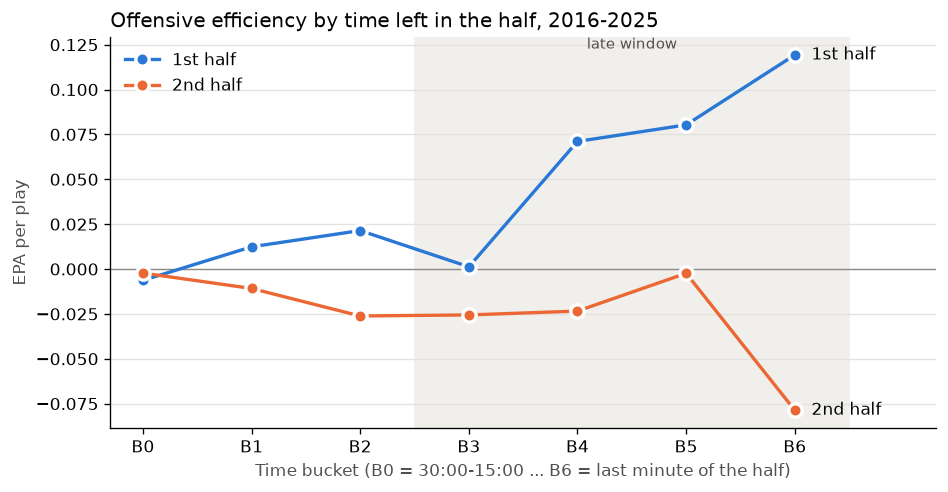

In [ ]:
import matplotlib.pyplot as plt

curve = (plays.groupby(["bucket", "game_half"], observed=True)["epa"]
              .mean().unstack("game_half").reindex(order))
colors = {"Half1": "#2a78d6", "Half2": "#eb6834"}

fig, ax = plt.subplots(figsize=(8, 4.2), dpi=120)
ax.axvspan(2.5, 6.5, color="#f0efec", zorder=0)          # late window = B3-B6
ax.axhline(0, color="#8a8984", lw=0.8, zorder=1)

for half, label in [("Half1", "1st half"), ("Half2", "2nd half")]:
    ax.plot(range(7), curve[half], color=colors[half], lw=2, marker="o", ms=8,
            markeredgecolor="white", markeredgewidth=2, label=label, zorder=3)
    ax.annotate(label, (6, curve[half].iloc[-1]), xytext=(10, 0),
                textcoords="offset points", va="center", fontsize=10)

ax.text(4.5, ax.get_ylim()[1], "late window", ha="center", va="top", color="#52514e", fontsize=9)
ax.set_xticks(range(7)); ax.set_xticklabels(order); ax.set_xlim(-0.3, 7.3)
ax.set_xlabel("Time bucket (B0 = 30:00-15:00 ... B6 = last minute of the half)", color="#52514e")
ax.set_ylabel("EPA per play", color="#52514e")
ax.set_title("Offensive efficiency by time left in the half, 2016-2025", loc="left")
ax.yaxis.grid(True, color="#e3e2de", lw=0.8); ax.set_axisbelow(True)
for s in ["top", "right"]: ax.spines[s].set_visible(False)
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()


## Findings (Claim A)

- **1st half: yes, at the play level.** EPA/play is about +0.08 higher in the last 4 minutes than the rest of the half (95% interval +0.066 to +0.092, resampling whole games), and positive in all 10 seasons. The rise starts in B4 (3:00 left), not at the start of the window.
- **2nd half: no.** EPA/play is slightly lower late (-0.019, interval -0.035 to -0.004) and drops in the final minute. 8 of 10 seasons are negative; 2024 and 2025 are positive, which may be noise.
- **Per drive, neither half surges.** TD rate falls late (1st half 24.3% → 16.3%, 2nd half 24.5% → 14.9%) because drives that start late have less time and settle for field goals. Any-score rate holds at about 40% in the 1st half until the last minute despite far less clock; in the 2nd half it falls from about 40% to about 21%.
- **Open:** why the halves differ (game state, H7/H8), and whether the 1st-half rise is the offense or soft coverage (H2).